
# Q-DICE Results Demo

This notebook exercises the reimplemented Q-DICE pipeline (`qdice/`) on the
same **classes** of experiments used in the paper's Results section:

1. Gate teleportation (the nonlocal-link primitive)
2. GHZ state generation across distributed nodes
3. Distributed Grover's search
4. Distributed Deutsch-Jozsa
5. A novel "ring-of-rings" architecture noise-threshold sweep

Each section uses **published, physically grounded noise parameters**
(T1, T2, link durations, and link error probabilities) sourced from
`qdice.reference_parameters`, which bundles the values transcribed
directly from the source papers referenced in the Q-DICE methodology.

**Important caveat:** configuring a noise model with a reference's
published parameters is *not* the same as reproducing that reference's
reported outcome. Our circuits, protocols, and noise-injection points are
a simplified reimplementation, not the exact experimental setup used in
any of these papers. Treat every fidelity/success-rate number produced
below as this reimplementation's own output when driven with realistic
link characteristics -- useful for exploring how the methodology responds
to real noise regimes, but not a validation against, or reproduction of,
the originally published results.


In [1]:

import sys, os
sys.path.insert(0, os.path.abspath('..'))

import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Kraus, Statevector, state_fidelity
from qiskit_aer import AerSimulator
from qiskit_aer.noise import depolarizing_error

from qdice.qpu_backend import QPUBackend, slice_qpu, stitch_qpus
from qdice.noise_models import (
    HamiltonianLinkParams,
    EntanglementLinkParams,
    hamiltonian_link_kraus,
    entanglement_link_kraus,
    build_density_matrix_noise_model,
)
from qdice.mapping import distributed_aware_mapping
from qdice.reference_parameters import get_reference_link_params, REFERENCE_NOISE_PARAMETERS

plt.rcParams["figure.figsize"] = (6, 4)

for name, entry in REFERENCE_NOISE_PARAMETERS.items():
    print(f"{name:28s} {entry['link_type']:22s} {entry}")


Chou_et_al                   Hamiltonian-Mediated   {'link_type': 'Hamiltonian-Mediated', 'T1': 5e-05, 'T2': 3e-05, 't_link': 2e-06}
Main_et_al                   Entanglement-Mediated  {'link_type': 'Entanglement-Mediated', 'p': 0.14, 't_link': None}
Iuliano_et_al                Entanglement-Mediated  {'link_type': 'Entanglement-Mediated', 'p': 0.235}
Pompili_et_al                Entanglement-Mediated  {'link_type': 'Entanglement-Mediated', 'p': 0.2}
Yan_et_al                    Hamiltonian-Mediated   {'link_type': 'Hamiltonian-Mediated', 'T1': 8e-05, 'T2': 5e-05, 't_link': 1.5e-06}
Tsujimoto_et_al              Entanglement-Mediated  {'link_type': 'Entanglement-Mediated', 'p': 0.16}
IBM_Marrakesh_Calibration    Hamiltonian-Mediated   {'link_type': 'Hamiltonian-Mediated', 'T1': 0.00017971, 'T2': 8.838e-05, 't_link': 7e-08}



## 1. Gate Teleportation

We implement the standard nonlocal-CNOT "telegate" protocol: a shared Bell
pair between two communication ancillas is consumed, together with two bits
of classical communication, to perform a CNOT between a control qubit on
one node and a target qubit on the other, with no direct physical
interaction between them.

Q-DICE's contribution at this stage is the **noise channel applied to the
shared Bell pair** immediately after it is generated -- this is where
nonlocal link imperfections enter the protocol. We inject either the
Hamiltonian-mediated channel (amplitude damping + phase damping from T1,
T2, and link duration) or the entanglement-mediated channel (two-qubit
depolarizing from a link error probability `p`), then measure how well the
protocol reproduces an ideal CNOT.

Fidelity is estimated as the average state fidelity between the protocol's
output and the ideal CNOT output, averaged over a small fixed set of input
test states (`|0>`, `|1>`, `|+>`, `|+i>` on each qubit). This is a cheap
proxy for full process fidelity, not a substitute for complete quantum
process tomography.


In [2]:

def nonlocal_cnot_circuit(prep_control, prep_target, kraus_channel=None):
    '''Build the nonlocal-CNOT telegate circuit with optional link noise
    injected on the freshly generated Bell pair.'''
    qr = QuantumRegister(4, "q")  # control, ancilla_A, ancilla_B, target
    cr = ClassicalRegister(2, "c")
    qc = QuantumCircuit(qr, cr)
    control, ancilla_a, ancilla_b, target = qr

    prep_control(qc, control)
    prep_target(qc, target)

    # Generate the shared Bell pair between the two communication ancillas.
    qc.h(ancilla_a)
    qc.cx(ancilla_a, ancilla_b)

    # Inject nonlocal link noise on the freshly generated entangled pair.
    if kraus_channel is not None:
        qc.append(kraus_channel.to_instruction(), [ancilla_a, ancilla_b])

    # Telegate protocol: entangle control with ancilla_A, measure, and
    # classically correct ancilla_B / control based on the outcomes.
    qc.cx(control, ancilla_a)
    qc.measure(ancilla_a, cr[0])
    with qc.if_test((cr[0], 1)):
        qc.x(ancilla_b)
    qc.cx(ancilla_b, target)
    qc.h(ancilla_b)
    qc.measure(ancilla_b, cr[1])
    with qc.if_test((cr[1], 1)):
        qc.z(control)

    qc.save_density_matrix(qubits=[control, target], label="ct")
    return qc


def _prep_0(qc, q):
    pass

def _prep_1(qc, q):
    qc.x(q)

def _prep_plus(qc, q):
    qc.h(q)

def _prep_plus_i(qc, q):
    qc.h(q)
    qc.s(q)

TEST_STATE_PREPS = [_prep_0, _prep_1, _prep_plus, _prep_plus_i]


def ideal_cnot_output(prep_control, prep_target):
    qc = QuantumCircuit(2)
    prep_control(qc, 0)
    prep_target(qc, 1)
    qc.cx(0, 1)
    return Statevector(qc)


_density_matrix_sim = AerSimulator(method="density_matrix")


def average_gate_fidelity(kraus_channel=None):
    '''Average state fidelity of the telegate protocol vs. an ideal CNOT,
    averaged over a small fixed grid of input test states.'''
    fidelities = []
    for prep_c in TEST_STATE_PREPS:
        for prep_t in TEST_STATE_PREPS:
            circuit = nonlocal_cnot_circuit(prep_c, prep_t, kraus_channel)
            result = _density_matrix_sim.run(circuit).result()
            dm = result.data(0)["ct"]
            ideal = ideal_cnot_output(prep_c, prep_t)
            fidelities.append(state_fidelity(dm, ideal))
    return float(np.mean(fidelities))


def kraus_for_link_params(params):
    '''Build the two-qubit Kraus channel appropriate to a link params object,
    for injection onto a freshly generated Bell pair.'''
    if isinstance(params, HamiltonianLinkParams):
        amp, phase = hamiltonian_link_kraus(params)
        single_qubit_channel = amp.compose(phase)
        return single_qubit_channel.tensor(single_qubit_channel)
    if isinstance(params, EntanglementLinkParams):
        return entanglement_link_kraus(params)
    raise TypeError(f"Unsupported link params type: {type(params)}")



Three of the paper's teleported-gate references are used here as
calibration inputs: **Chou et al.** (Hamiltonian-mediated, superconducting
microwave cavity bus), **Main et al.** (entanglement-mediated, trapped-ion
optical link), and **Iuliano et al.** (entanglement-mediated, NV-diamond
optical link). We compute this reimplementation's own average gate
fidelity for the telegate protocol under each reference's published link
parameters.


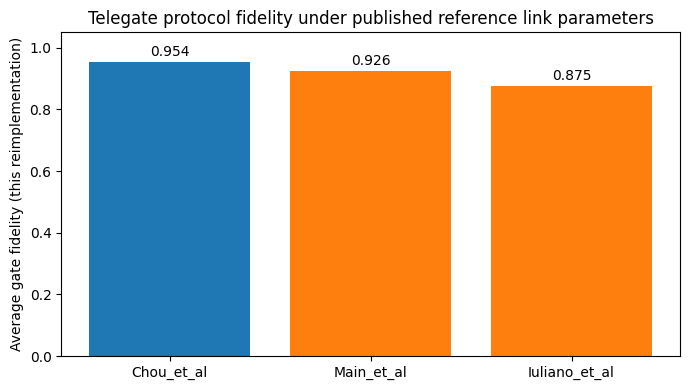

Chou_et_al: this reimplementation's average gate fidelity = 0.9535 (link params: {'link_type': 'Hamiltonian-Mediated', 'T1': 5e-05, 'T2': 3e-05, 't_link': 2e-06})
Main_et_al: this reimplementation's average gate fidelity = 0.9256 (link params: {'link_type': 'Entanglement-Mediated', 'p': 0.14, 't_link': None})
Iuliano_et_al: this reimplementation's average gate fidelity = 0.8752 (link params: {'link_type': 'Entanglement-Mediated', 'p': 0.235})


In [3]:

teleportation_references = ["Chou_et_al", "Main_et_al", "Iuliano_et_al"]
teleportation_fidelities = []

for ref_name in teleportation_references:
    params = get_reference_link_params(ref_name)
    channel = kraus_for_link_params(params)
    teleportation_fidelities.append(average_gate_fidelity(channel))

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(teleportation_references, teleportation_fidelities,
              color=["tab:blue", "tab:orange", "tab:orange"])
ax.set_ylabel("Average gate fidelity (this reimplementation)")
ax.set_title("Telegate protocol fidelity under published reference link parameters")
ax.set_ylim(0, 1.05)
for bar, fid in zip(bars, teleportation_fidelities):
    ax.text(bar.get_x() + bar.get_width() / 2, fid + 0.02, f"{fid:.3f}", ha="center")
plt.tight_layout()
plt.show()

for ref_name, fid in zip(teleportation_references, teleportation_fidelities):
    print(f"{ref_name}: this reimplementation's average gate fidelity = {fid:.4f} "
          f"(link params: {REFERENCE_NOISE_PARAMETERS[ref_name]})")



For additional context, the cell below also sweeps noise strength
continuously (varying `t_link` for a Hamiltonian-mediated link, and `p` for
an entanglement-mediated link) rather than only evaluating at the three
fixed reference points above.


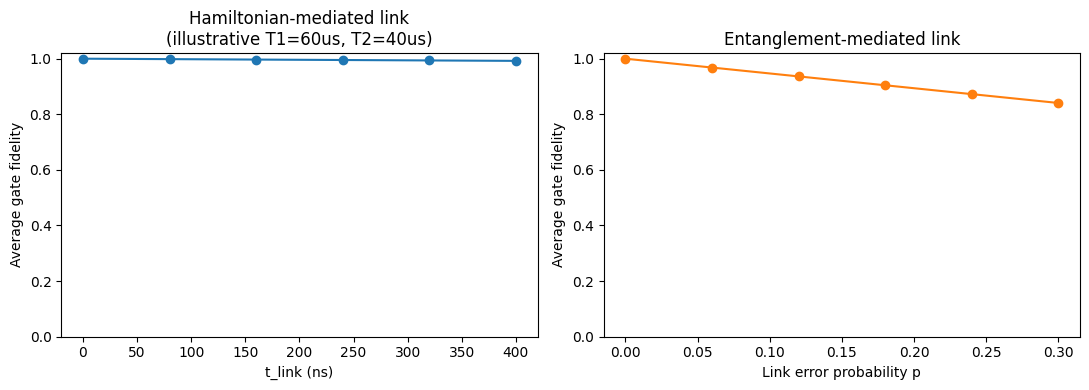

In [4]:

t_link_values_ns = np.linspace(0, 400, 6)
hamiltonian_fidelities = []
for t_link in t_link_values_ns:
    params = HamiltonianLinkParams(t1_us=60.0, t2_us=40.0, t_link_ns=t_link)
    hamiltonian_fidelities.append(average_gate_fidelity(kraus_for_link_params(params)))

p_values = np.linspace(0, 0.3, 6)
entanglement_fidelities = []
for p in p_values:
    params = EntanglementLinkParams(link_error_probability=p, t_link_ns=0.0)
    entanglement_fidelities.append(average_gate_fidelity(kraus_for_link_params(params)))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(t_link_values_ns, hamiltonian_fidelities, "o-", color="tab:blue")
axes[0].set_xlabel("t_link (ns)")
axes[0].set_ylabel("Average gate fidelity")
axes[0].set_title("Hamiltonian-mediated link\n(illustrative T1=60us, T2=40us)")
axes[0].set_ylim(0, 1.02)

axes[1].plot(p_values, entanglement_fidelities, "o-", color="tab:orange")
axes[1].set_xlabel("Link error probability p")
axes[1].set_ylabel("Average gate fidelity")
axes[1].set_title("Entanglement-mediated link")
axes[1].set_ylim(0, 1.02)

plt.tight_layout()
plt.show()



## 2. GHZ State Generation

A three-node backend is built with QPU stitching in a linear-chain
topology (node A -- node B -- node C), and a GHZ state is prepared by
cascading nonlocal CNOTs across the two virtual links. The circuit is
mapped onto the backend with the boundary-aware mapping algorithm, then
simulated with the same link noise model applied to both nonlocal links.

The paper validates its GHZ-generation benchmark against three references
spanning both link paradigms: **Pompili et al.** (entanglement-mediated,
NV-center optical fiber network), **Yan et al.** (Hamiltonian-mediated,
triangular superconducting transmon network), and **Tsujimoto et al.**
(entanglement-mediated, asynchronous telecom photon pair sources). We use
each reference's published parameters as calibration inputs below.


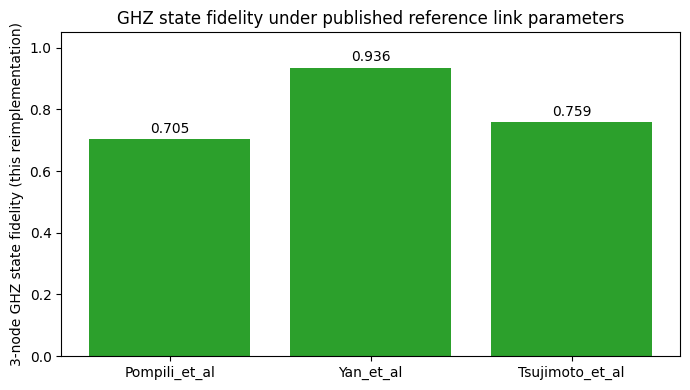

In [5]:

def build_chain_backend(n_nodes):
    nodes = {f"N{i}": QPUBackend(num_qubits=1, coupling_map=[]) for i in range(n_nodes)}
    links = [(f"N{i}", 0, f"N{i+1}", 0) for i in range(n_nodes - 1)]
    return stitch_qpus(nodes, links)


def ghz_ideal_state(n):
    ideal_circuit = QuantumCircuit(n)
    ideal_circuit.h(0)
    for i in range(n - 1):
        ideal_circuit.cx(i, i + 1)
    return Statevector(ideal_circuit)


def ghz_fidelity_for_params(n_nodes, link_params):
    backend = build_chain_backend(n_nodes)
    n = backend.num_qubits

    virtual_circuit = QuantumCircuit(n)
    virtual_circuit.h(0)
    for i in range(n - 1):
        virtual_circuit.cx(i, i + 1)

    virtual_partitions = {i: f"N{i}" for i in range(n)}
    communication_ancillas = {i: i for i in range(n)}
    mapped = distributed_aware_mapping(
        virtual_circuit, backend, virtual_partitions, communication_ancillas,
        num_iterations=10, seed=0,
    )

    if isinstance(link_params, HamiltonianLinkParams):
        noise_model = build_density_matrix_noise_model(
            hamiltonian_edges=[(edge, link_params) for edge in backend.nonlocal_edges],
            nonlocal_gate_name="cx",
        )
    else:
        noise_model = build_density_matrix_noise_model(
            entanglement_edges=[(edge, link_params) for edge in backend.nonlocal_edges],
            nonlocal_gate_name="cx",
        )

    circuit = mapped.circuit.copy()
    circuit.save_density_matrix()
    sim = AerSimulator(method="density_matrix", noise_model=noise_model)
    dm = sim.run(circuit).result().data(0)["density_matrix"]
    return state_fidelity(dm, ghz_ideal_state(n))


ghz_references = ["Pompili_et_al", "Yan_et_al", "Tsujimoto_et_al"]
ghz_fidelities_by_ref = [
    ghz_fidelity_for_params(3, get_reference_link_params(name)) for name in ghz_references
]

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(ghz_references, ghz_fidelities_by_ref, color="tab:green")
ax.set_ylabel("3-node GHZ state fidelity (this reimplementation)")
ax.set_title("GHZ state fidelity under published reference link parameters")
ax.set_ylim(0, 1.05)
for bar, fid in zip(bars, ghz_fidelities_by_ref):
    ax.text(bar.get_x() + bar.get_width() / 2, fid + 0.02, f"{fid:.3f}", ha="center")
plt.tight_layout()
plt.show()



For additional context, the cell below sweeps the entanglement-mediated
link error probability continuously rather than only evaluating at the
fixed reference points above.


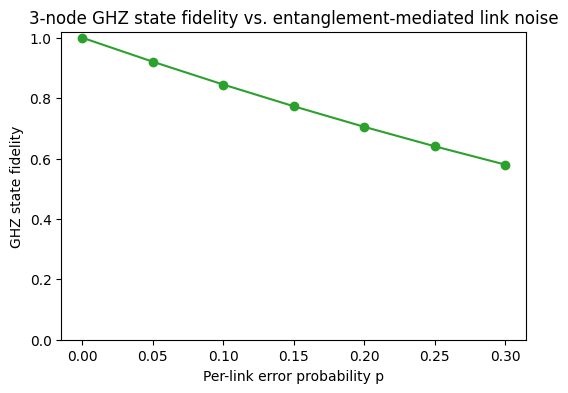

In [6]:

def ghz_fidelity_vs_p(n_nodes, p_values):
    return [
        ghz_fidelity_for_params(n_nodes, EntanglementLinkParams(link_error_probability=p, t_link_ns=0.0))
        for p in p_values
    ]

p_values = np.linspace(0, 0.3, 7)
ghz_fidelities = ghz_fidelity_vs_p(3, p_values)

plt.plot(p_values, ghz_fidelities, "o-", color="tab:green")
plt.xlabel("Per-link error probability p")
plt.ylabel("GHZ state fidelity")
plt.title("3-node GHZ state fidelity vs. entanglement-mediated link noise")
plt.ylim(0, 1.02)
plt.show()



## 3. Distributed Grover's Search

A minimal 2-qubit Grover's search (oracle marking `|11>`, single
Grover iteration) is distributed across two single-qubit nodes connected
by one virtual nonlocal link. The oracle and diffusion operator's
entangling gate are compiled with the boundary-aware mapping algorithm.

The paper's primary quantitative benchmark for this experiment is **Main
et al.**'s distributed 2-qubit Grover's search over an entanglement-mediated
optical link. We use that reference's published link error probability as
the calibration input.


In [7]:

def build_two_qubit_grover_circuit():
    qc = QuantumCircuit(2, 2)
    qc.h([0, 1])
    qc.cz(0, 1)  # oracle: marks |11>
    qc.h([0, 1]); qc.x([0, 1])
    qc.cz(0, 1)
    qc.x([0, 1]); qc.h([0, 1])
    qc.measure([0, 1], [0, 1])
    return qc


def grover_backend_and_mapped_circuit():
    node_a = QPUBackend(num_qubits=1, coupling_map=[])
    node_b = QPUBackend(num_qubits=1, coupling_map=[])
    backend = stitch_qpus({"A": node_a, "B": node_b}, stitch_links=[("A", 0, "B", 0)])
    circuit = build_two_qubit_grover_circuit()
    mapped = distributed_aware_mapping(
        circuit, backend, {0: "A", 1: "B"}, {0: 0, 1: 1}, num_iterations=10, seed=1
    )
    return backend, mapped.circuit


def grover_success_rate(link_params, shots=4000):
    backend, mapped_circuit = grover_backend_and_mapped_circuit()
    noise_model = build_density_matrix_noise_model(
        entanglement_edges=[(backend.nonlocal_edges[0], link_params)],
        nonlocal_gate_name="cx",  # cz decomposes to h-cx-h in the default basis
    )
    sim = AerSimulator(noise_model=noise_model)
    counts = sim.run(mapped_circuit, shots=shots).result().get_counts()
    return counts.get("11", 0) / shots


main_et_al_params = get_reference_link_params("Main_et_al")
grover_success_main = grover_success_rate(main_et_al_params)
print(f"Distributed Grover's search success rate under Main et al. link "
      f"parameters (p={main_et_al_params.link_error_probability}): "
      f"{grover_success_main:.4f} (this reimplementation's own simulated output)")


Distributed Grover's search success rate under Main et al. link parameters (p=0.14): 0.8113 (this reimplementation's own simulated output)



For additional context, the cell below sweeps the link error probability
continuously, marking where the Main et al. reference point falls on the
resulting curve.


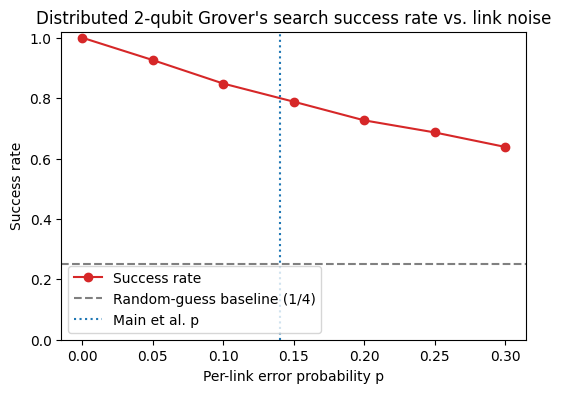

In [8]:

p_values = np.linspace(0, 0.3, 7)
grover_success = [
    grover_success_rate(EntanglementLinkParams(link_error_probability=p, t_link_ns=0.0))
    for p in p_values
]

plt.plot(p_values, grover_success, "o-", color="tab:red", label="Success rate")
plt.axhline(0.25, linestyle="--", color="gray", label="Random-guess baseline (1/4)")
plt.axvline(main_et_al_params.link_error_probability, linestyle=":", color="tab:blue",
            label="Main et al. p")
plt.xlabel("Per-link error probability p")
plt.ylabel("Success rate")
plt.title("Distributed 2-qubit Grover's search success rate vs. link noise")
plt.ylim(0, 1.02)
plt.legend()
plt.show()



## 4. Distributed Deutsch-Jozsa

We use a star-topology oracle (as in the paper's discussion): all query
qubits live on one node, the ancilla lives on another, and every
query-to-ancilla CNOT is a nonlocal operation across its own virtual link.
We compare a noiseless monolithic baseline against a distributed
implementation using **IBM Marrakesh's device calibration** (the same
hardware the paper's Deutsch-Jozsa hardware-mode experiments were run on)
as the Hamiltonian-mediated link parameters, as the number of query qubits
(and therefore the number of nonlocal operations per circuit) grows.


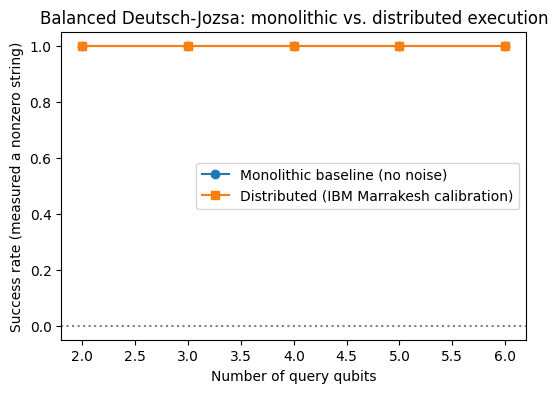

IBM Marrakesh calibration parameters used: {'link_type': 'Hamiltonian-Mediated', 'T1': 0.00017971, 'T2': 8.838e-05, 't_link': 7e-08}


In [9]:

def build_balanced_dj_circuit(n_query):
    ancilla = n_query
    qc = QuantumCircuit(n_query + 1, n_query)
    qc.x(ancilla)
    qc.h(range(n_query + 1))
    for i in range(n_query):
        qc.cx(i, ancilla)  # balanced (parity) oracle
    qc.h(range(n_query))
    qc.measure(range(n_query), range(n_query))
    return qc


def dj_success_rate(n_query, noise_model=None, use_mapping=True, shots=4000):
    ancilla = n_query
    circuit = build_balanced_dj_circuit(n_query)

    if use_mapping:
        node_a = QPUBackend(num_qubits=n_query, coupling_map=[])
        node_b = QPUBackend(num_qubits=1, coupling_map=[])
        stitch_links = [("A", i, "B", 0) for i in range(n_query)]
        backend = stitch_qpus({"A": node_a, "B": node_b}, stitch_links)

        virtual_partitions = {i: "A" for i in range(n_query)}
        virtual_partitions[ancilla] = "B"
        communication_ancillas = {i: i for i in range(n_query)}
        communication_ancillas[ancilla] = n_query
        mapped = distributed_aware_mapping(
            circuit, backend, virtual_partitions, communication_ancillas,
            num_iterations=10, seed=2,
        )
        run_circuit = mapped.circuit
    else:
        run_circuit = circuit

    sim = AerSimulator(noise_model=noise_model)
    counts = sim.run(run_circuit, shots=shots).result().get_counts()
    all_zero = "0" * n_query
    non_zero_counts = sum(v for k, v in counts.items() if k != all_zero)
    return non_zero_counts / shots


query_sizes = [2, 3, 4, 5, 6]
monolithic_success = []
distributed_success = []

marrakesh_params = get_reference_link_params("IBM_Marrakesh_Calibration")

for n_query in query_sizes:
    monolithic_success.append(dj_success_rate(n_query, noise_model=None, use_mapping=False))

    node_edges = [(i, n_query) for i in range(n_query)]
    noise_model = build_density_matrix_noise_model(
        hamiltonian_edges=[(edge, marrakesh_params) for edge in node_edges],
        nonlocal_gate_name="cx",
    )
    distributed_success.append(dj_success_rate(n_query, noise_model=noise_model, use_mapping=True))

plt.plot(query_sizes, monolithic_success, "o-", label="Monolithic baseline (no noise)")
plt.plot(query_sizes, distributed_success, "s-", label="Distributed (IBM Marrakesh calibration)")
plt.axhline(0.0, linestyle=":", color="gray")
plt.xlabel("Number of query qubits")
plt.ylabel("Success rate (measured a nonzero string)")
plt.title("Balanced Deutsch-Jozsa: monolithic vs. distributed execution")
plt.ylim(-0.05, 1.05)
plt.legend()
plt.show()

print(f"IBM Marrakesh calibration parameters used: {REFERENCE_NOISE_PARAMETERS['IBM_Marrakesh_Calibration']}")



## 5. Novel System Architecture: Ring-of-Rings Graph State

Finally, we build a small "ring-of-rings" style architecture with QPU
stitching: five 2-qubit modules (one computational qubit, one
communication ancilla), with adjacent modules' ancillas connected in a
ring. A 10-qubit graph state is prepared by applying `CZ` along every edge
of the architectural graph (local module edges plus the ring edges), and
we sweep the per-link depolarizing error probability to trace out a
fidelity curve -- the kind of noise-threshold sweep that is impractical on
physical hardware but cheap in simulation.

This is a novel topology with no direct experimental reference, so instead
of a fixed calibration point we mark where two of the paper's published
entanglement-mediated link error probabilities (**Main et al.**, **Pompili
et al.**) fall along our own simulated curve, purely for context on what
"near-term achievable" link quality looks like relative to this
architecture's noise sensitivity.


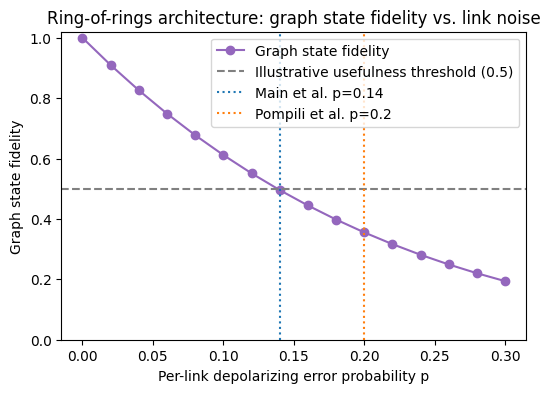

In this reimplementation's simulation, fidelity first drops below 0.5 near p = 0.140.


In [10]:

def build_ring_of_rings_backend(n_modules):
    modules = {f"M{i}": QPUBackend(num_qubits=2, coupling_map=[(0, 1)]) for i in range(n_modules)}
    links = [(f"M{i}", 1, f"M{(i + 1) % n_modules}", 1) for i in range(n_modules)]
    return stitch_qpus(modules, links)


def ring_of_rings_graph_state_fidelity(backend, p_values):
    n = backend.num_qubits
    circuit = QuantumCircuit(n)
    circuit.h(range(n))
    for a, b in backend.coupling_map:
        circuit.cz(a, b)
    ideal_state = Statevector(circuit)

    fidelities = []
    for p in p_values:
        params = EntanglementLinkParams(link_error_probability=p, t_link_ns=0.0)
        noise_model = build_density_matrix_noise_model(
            entanglement_edges=[(edge, params) for edge in backend.nonlocal_edges],
            nonlocal_gate_name="cz",  # cz is native here; no basis decomposition occurs
        )
        noisy_circuit = circuit.copy()
        noisy_circuit.save_density_matrix()
        sim = AerSimulator(method="density_matrix", noise_model=noise_model)
        dm = sim.run(noisy_circuit).result().data(0)["density_matrix"]
        fidelities.append(state_fidelity(dm, ideal_state))
    return fidelities


ring_backend = build_ring_of_rings_backend(5)
p_values = np.linspace(0.0, 0.3, 16)
ring_fidelities = ring_of_rings_graph_state_fidelity(ring_backend, p_values)

main_p = get_reference_link_params("Main_et_al").link_error_probability
pompili_p = get_reference_link_params("Pompili_et_al").link_error_probability

plt.plot(p_values, ring_fidelities, "o-", color="tab:purple", label="Graph state fidelity")
plt.axhline(0.5, linestyle="--", color="gray", label="Illustrative usefulness threshold (0.5)")
plt.axvline(main_p, linestyle=":", color="tab:blue", label=f"Main et al. p={main_p}")
plt.axvline(pompili_p, linestyle=":", color="tab:orange", label=f"Pompili et al. p={pompili_p}")
plt.xlabel("Per-link depolarizing error probability p")
plt.ylabel("Graph state fidelity")
plt.title("Ring-of-rings architecture: graph state fidelity vs. link noise")
plt.ylim(0, 1.02)
plt.legend()
plt.show()

below_half = [p for p, f in zip(p_values, ring_fidelities) if f < 0.5]
if below_half:
    print(f"In this reimplementation's simulation, fidelity first drops below 0.5 "
          f"near p = {below_half[0]:.3f}.")
else:
    print("Fidelity stayed above 0.5 across the full swept range.")



## Notes

- All link parameters used above (except the generic continuous sweeps,
  which are explicitly labeled as illustrative) are taken directly from
  `qdice.reference_parameters.REFERENCE_NOISE_PARAMETERS`, itself
  transcribed from the source papers cited in each section.
- Configuring a noise model with a reference's parameters is not the same
  as reproducing that reference's reported outcome -- our simplified
  circuits and noise-injection points differ from the actual experimental
  protocols, so the fidelities/success-rates above are this
  reimplementation's own output, not a validation against the literature.
- The "average gate fidelity" used in Section 1 is a fast proxy over a
  small grid of test states, not full quantum process tomography.
- All backends, circuits, and topologies here are toy-sized so the whole
  notebook runs quickly; the same `qdice` functions apply unchanged to
  larger backends and circuits.
